<a href="https://colab.research.google.com/github/ML-HW-SYS/a4-AaronGoldblatt/blob/main/1-numerical_precision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Numerical Precision

In this section, you will investigate how different convolution
and matrix-matrix multiplication kernel performs when changing the
numerical precision.

## 1. Set-up

In [1]:
# Mount google drive
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [2]:
# Make sure your token is stored in a txt file at the location below.
# This way there is no risk that you will push it to your repo
# Never share your token with anyone, it is basically your github password!
with open('/content/gdrive/MyDrive/ece5545/token.txt') as f:
    token = f.readline().strip()
# Use another file to store your github username
with open('/content/gdrive/MyDrive/ece5545/git_username.txt') as f:
    handle = f.readline().strip()

In [3]:
# Clone your github repo
YOUR_TOKEN = token
YOUR_HANDLE = handle
BRANCH = "main"

%mkdir /content/gdrive/MyDrive/ece5545
%cd /content/gdrive/MyDrive/ece5545
!git clone https://{YOUR_TOKEN}@github.com/ML-HW-SYS/a4-{YOUR_HANDLE}.git
%cd /content/gdrive/MyDrive/ece5545/a4-{YOUR_HANDLE}
!git checkout {BRANCH}
!git pull

PROJECT_ROOT = f"/content/gdrive/MyDrive/ece5545/a4-{YOUR_HANDLE}"

mkdir: cannot create directory ‘/content/gdrive/MyDrive/ece5545’: File exists
/content/gdrive/MyDrive/ece5545
fatal: destination path 'a4-AaronGoldblatt' already exists and is not an empty directory.
/content/gdrive/MyDrive/ece5545/a4-AaronGoldblatt
Already on 'main'
Your branch is up to date with 'origin/main'.
remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 3 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (3/3), 451.81 KiB | 6.11 MiB/s, done.
From https://github.com/ML-HW-SYS/a4-AaronGoldblatt
   49ae099..cab7272  main       -> origin/main
Updating 49ae099..cab7272
Fast-forward
 2-svd_rank.ipynb | 3493 +++++++++++++++++++++++++++++++++++++++++++++++++-----
 1 file changed, 3191 insertions(+), 302 deletions(-)


In [4]:
# This extension reloads all imports before running each cell
%load_ext autoreload
%autoreload 2

Verify the following cell prints your github repository.

In [5]:
!ls {PROJECT_ROOT}

1-numerical_precision.ipynb	 svd_errors_by_rank_and_precision.png
2-svd_rank.ipynb		 svd_rank_Cat_Image.png
comparison_errors_log_scale.png  svd_rank_MNIST_Activations.png
comparison_errors.png		 svd_rank_MNIST_Batch.png
data				 svd_rank_Neural_Network_Weights.png
fft_error_log_plot.png		 svd_rank_Random_Matrix.png
im2col_error_log_plot.png	 svd_speedup_mnist_act_weight_combined_log.png
logmatmul_error_log_plot.png	 svd_speedup_mnist_act_weight_combined.png
mnist.py			 svd_speedup_mnist_act_weight.png
README.md			 tests
src				 winograd_error_plots.png
svd_combined_error_plot.png


In [6]:
!pip install torch numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 91.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 70.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 99.8 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitlin

In [7]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from src.matmul import matmul
from src.conv2d import conv2d

In [8]:
!pip install pytest

In [9]:
!python -m pytest

============================= test session starts ==============================
platform linux -- Python 3.11.12, pytest-8.3.5, pluggy-1.5.0
rootdir: /content/gdrive/MyDrive/ece5545/a4-AaronGoldblatt
plugins: langsmith-0.3.33, typeguard-4.4.2, anyio-4.9.0
collected 168 items                                                            

tests/test_conv2d.py ................................................... [ 30%]
.................................                                        [ 50%]
tests/test_matmul.py ................................................... [ 80%]
.................................                                        [100%]

======================== 168 passed in 95.42s (0:01:35) ========================


# 2. Convolution

In the following cell(s), please plot the reconstruction error of an
approximated tensor (in the y-axis) with the numerical precision
(in the x-axis). Please show one plot for `winograd` and one plot for `fft`.

In [10]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [11]:
# Set up test data
def conv2d_generate_test_data(precision):
    dtype_map = {
        16: torch.float16,
        32: torch.float32,
        64: torch.float64
    }
    dtype = dtype_map[precision]

    # Create 2D input and kernel as per the function requirements
    # x: (H, W) tensor
    # k: (Hk, Wk) tensor
    # b: scalar

    # For example 32x32 input and 3x3 kernel
    x = torch.randn(32, 32, dtype=dtype)
    k = torch.randn(3, 3, dtype=dtype)
    b = torch.tensor(0.1, dtype=dtype)  # Scalar bias

    return x, k, b

In [12]:
# Calculate L1 reconstruction error
def calculate_error(naive_result, method_result):
    # L1 norm of the difference
    return torch.sum(
        torch.abs(naive_result - method_result)
    ).item()

Running Winograd tests...
  float16 error: 1.0978889465332031
  float32 error: 0.00028469786047935486
  float64 error: 7.3445294100416e-05


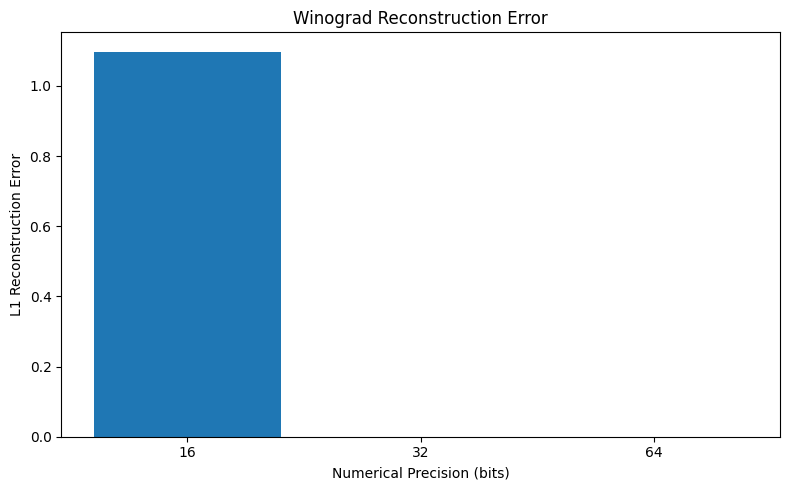

In [13]:
from src.conv2d import winograd
# TODO: plot the error v.s. precision curve

# Precision levels to test for Winograd
precisions_winograd = [16, 32, 64]
winograd_errors = []

# Run tests for Winograd at each precision
print("Running Winograd tests...")
for precision in precisions_winograd:
    try:
        x, k, b = conv2d_generate_test_data(precision)

        # Naive (ground truth) implementation
        naive_result = conv2d(x, k, b, method='naive')

        # Winograd implementation
        winograd_result = conv2d(x, k, b, method='winograd')
        winograd_error = calculate_error(naive_result, winograd_result)
        winograd_errors.append(winograd_error)
        print(f"  float{precision} error: {winograd_error}")
    except Exception as e:
        print(f"  float{precision} failed: {str(e)}")
        winograd_errors.append(0)  # Add placeholder for plotting

# Plot Winograd results
plt.figure(figsize=(8, 5))
plt.bar([str(p) for p in precisions_winograd], winograd_errors)
plt.title('Winograd Reconstruction Error')
plt.xlabel('Numerical Precision (bits)')
plt.ylabel('L1 Reconstruction Error')
plt.tight_layout()
plt.show()

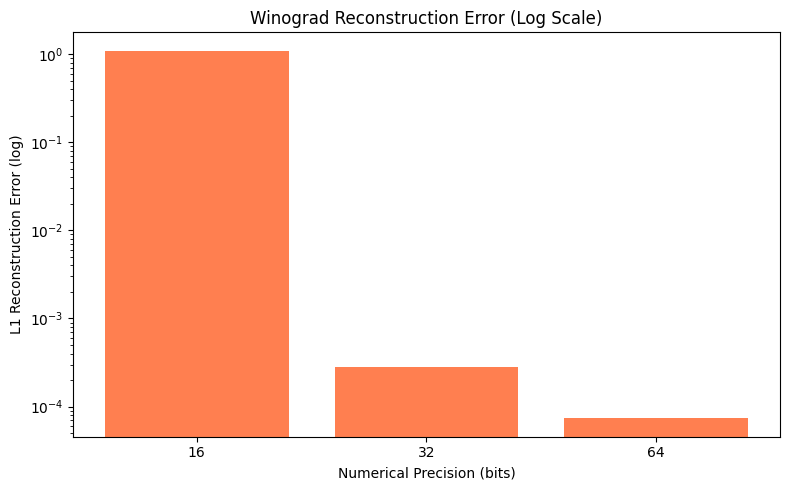

In [14]:
# Plot Winograd results with log scale
plt.figure(figsize=(8, 5))
plt.bar([str(p) for p in precisions_winograd], winograd_errors, color='coral')
plt.yscale('log')  # Add this line to use log scale
plt.title('Winograd Reconstruction Error (Log Scale)')
plt.xlabel('Numerical Precision (bits)')
plt.ylabel('L1 Reconstruction Error (log)')
plt.tight_layout()
plt.show()

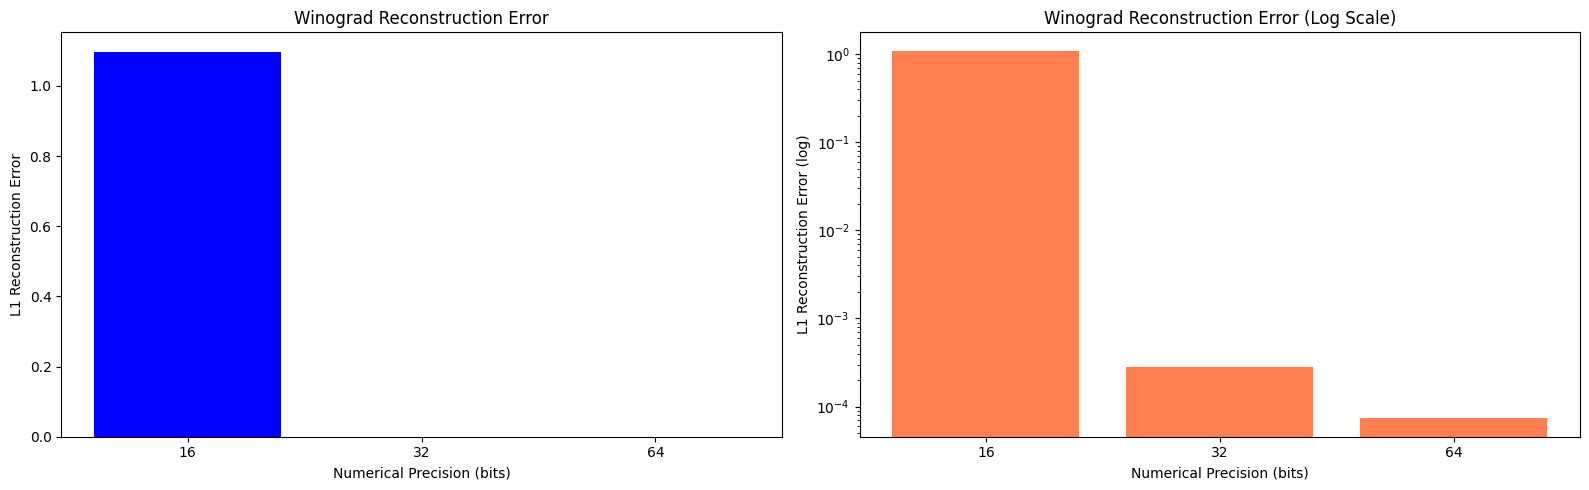

In [15]:
# Combined plot with regular and log scale side by side for Winograd
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# First subplot - regular scale
ax1.bar([str(p) for p in precisions_winograd], winograd_errors, color='blue')
ax1.set_title('Winograd Reconstruction Error')
ax1.set_xlabel('Numerical Precision (bits)')
ax1.set_ylabel('L1 Reconstruction Error')

# Second subplot - log scale
ax2.bar([str(p) for p in precisions_winograd], winograd_errors, color='coral')
ax2.set_yscale('log')
ax2.set_title('Winograd Reconstruction Error (Log Scale)')
ax2.set_xlabel('Numerical Precision (bits)')
ax2.set_ylabel('L1 Reconstruction Error (log)')

plt.tight_layout()
plt.show()

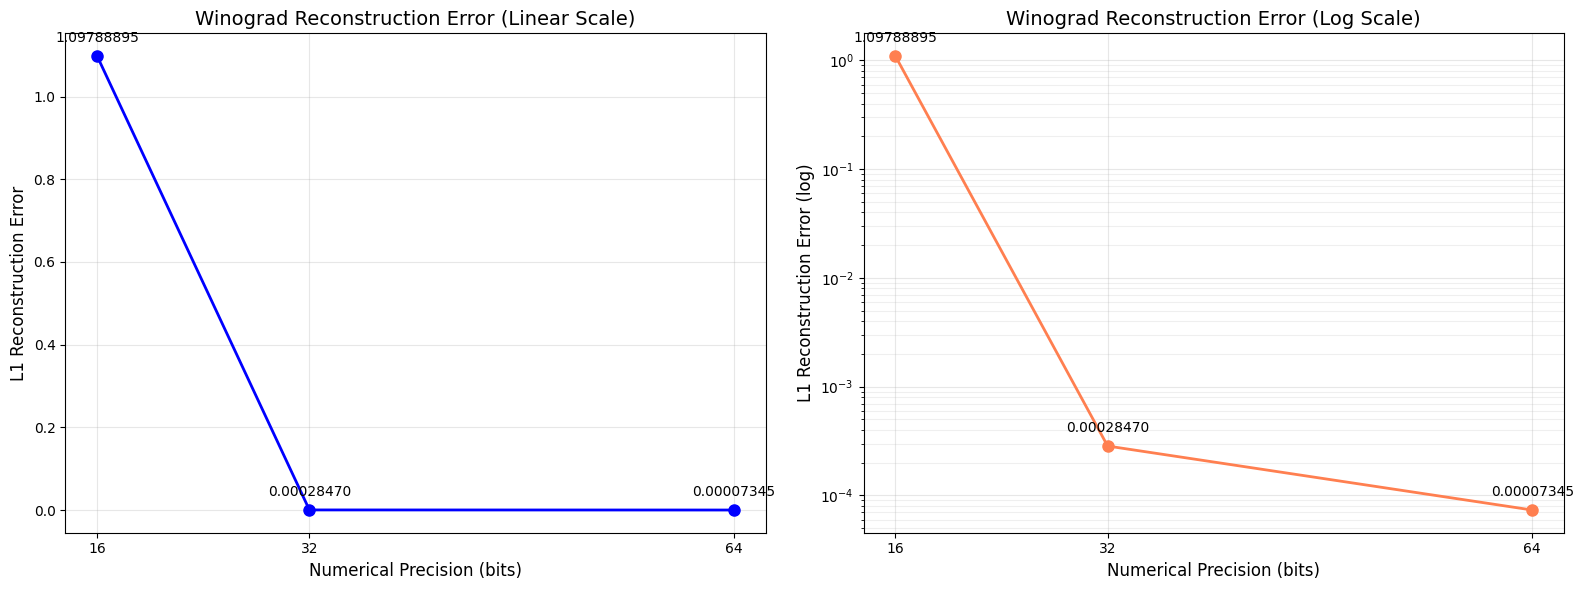

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Data from your Winograd tests
precisions = [16, 32, 64]
errors = [1.0978889465332031, 0.00028469786047935486, 7.3445294100416e-05]

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Regular scale plot
ax1.plot(precisions, errors, 'o-', color='blue', linewidth=2, markersize=8)
ax1.set_title('Winograd Reconstruction Error (Linear Scale)', fontsize=14)
ax1.set_xlabel('Numerical Precision (bits)', fontsize=12)
ax1.set_ylabel('L1 Reconstruction Error', fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.set_xticks(precisions)

# Annotate points on linear scale
for i, (x, y) in enumerate(zip(precisions, errors)):
    ax1.annotate(f"{y:.8f}", 
                 (x, y), 
                 textcoords="offset points",
                 xytext=(0, 10), 
                 ha='center')

# Log scale plot
ax2.plot(precisions, errors, 'o-', color='coral', linewidth=2, markersize=8)
ax2.set_title('Winograd Reconstruction Error (Log Scale)', fontsize=14)
ax2.set_xlabel('Numerical Precision (bits)', fontsize=12)
ax2.set_ylabel('L1 Reconstruction Error (log)', fontsize=12)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)
ax2.grid(True, which='minor', alpha=0.2)
ax2.set_xticks(precisions)

# Annotate points on log scale
for i, (x, y) in enumerate(zip(precisions, errors)):
    ax2.annotate(f"{y:.8f}", 
                 (x, y), 
                 textcoords="offset points",
                 xytext=(0, 10), 
                 ha='center')

plt.tight_layout()
# plt.savefig('winograd_error_comparison.png', dpi=300)
plt.show()


Running FFT tests...
  float32 error: 0.0004819110035896301
  float64 error: 4.088022463254182e-05


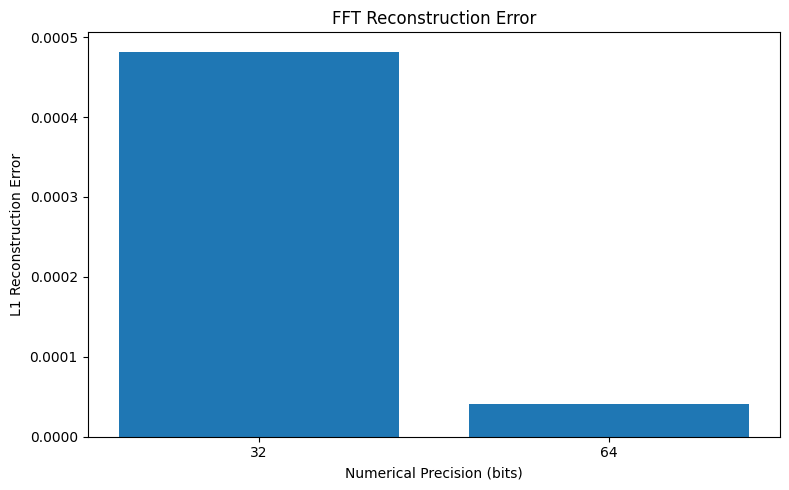

In [16]:
from src.conv2d import fft
# TODO: plot the error v.s. precision curve

# Precision levels to test for FFT (no float16 support)
precisions_fft = [32, 64]
fft_errors = []

# Run tests for FFT at each precision
print("\nRunning FFT tests...")
for precision in precisions_fft:
    try:
        x, k, b = conv2d_generate_test_data(precision)

        # Naive (ground truth) implementation
        naive_result = conv2d(x, k, b, method='naive')

        # FFT implementation
        fft_result = conv2d(x, k, b, method='fft')
        fft_error = calculate_error(naive_result, fft_result)
        fft_errors.append(fft_error)
        print(f"  float{precision} error: {fft_error}")
    except Exception as e:
        print(f"  float{precision} failed: {str(e)}")
        fft_errors.append(0)  # Add placeholder for plotting

# Plot FFT results
plt.figure(figsize=(8, 5))
plt.bar([str(p) for p in precisions_fft], fft_errors)
plt.title('FFT Reconstruction Error')
plt.xlabel('Numerical Precision (bits)')
plt.ylabel('L1 Reconstruction Error')
plt.tight_layout()
plt.show()

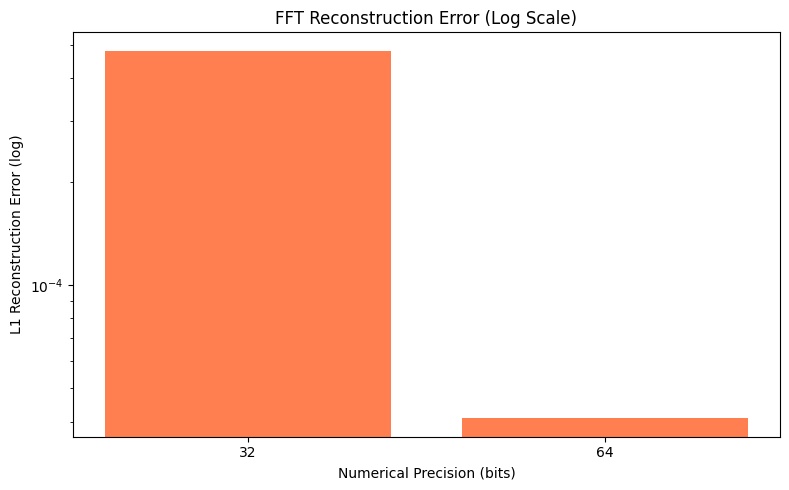

In [17]:
# Plot FFT results with log scale in coral color
plt.figure(figsize=(8, 5))
plt.bar([str(p) for p in precisions_fft], fft_errors, color='coral')
plt.yscale('log')  # Use log scale for y-axis
plt.title('FFT Reconstruction Error (Log Scale)')
plt.xlabel('Numerical Precision (bits)')
plt.ylabel('L1 Reconstruction Error (log)')
plt.tight_layout()
# plt.savefig('fft_error_log_plot.png')  # Save the plot
plt.show()

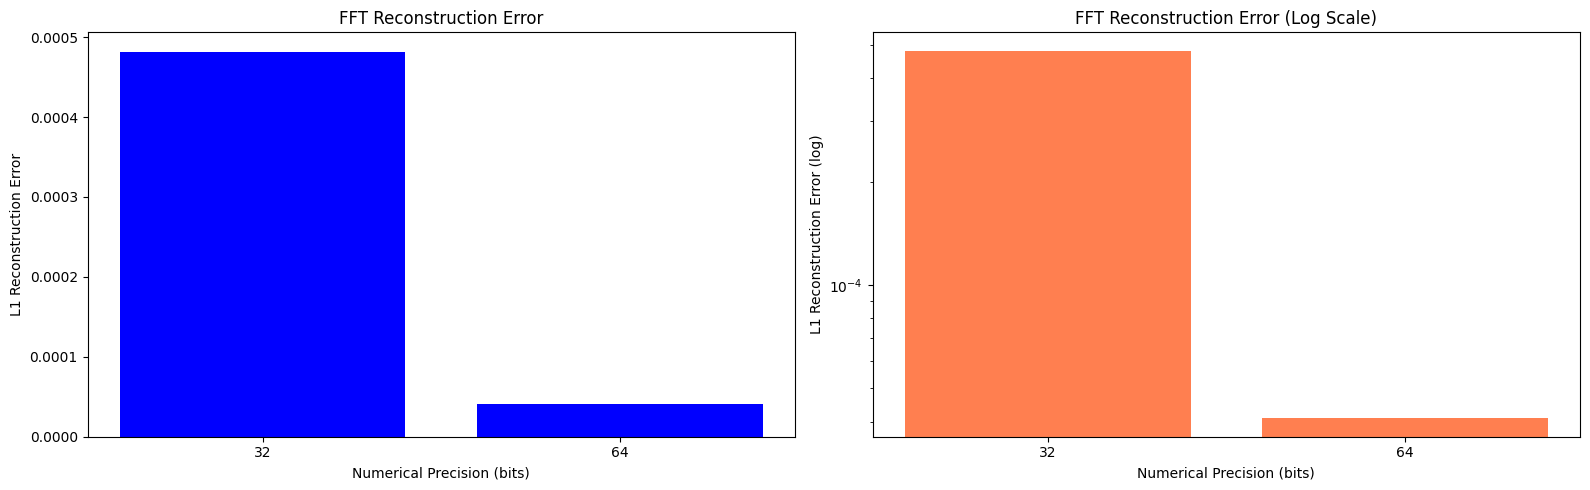

In [18]:
# Combined plot with regular and log scale side by side for FFT
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# First subplot - regular scale
ax1.bar([str(p) for p in precisions_fft], fft_errors, color='blue')
ax1.set_title('FFT Reconstruction Error')
ax1.set_xlabel('Numerical Precision (bits)')
ax1.set_ylabel('L1 Reconstruction Error')

# Second subplot - log scale
ax2.bar([str(p) for p in precisions_fft], fft_errors, color='coral')
ax2.set_yscale('log')
ax2.set_title('FFT Reconstruction Error (Log Scale)')
ax2.set_xlabel('Numerical Precision (bits)')
ax2.set_ylabel('L1 Reconstruction Error (log)')

plt.tight_layout()
plt.show()

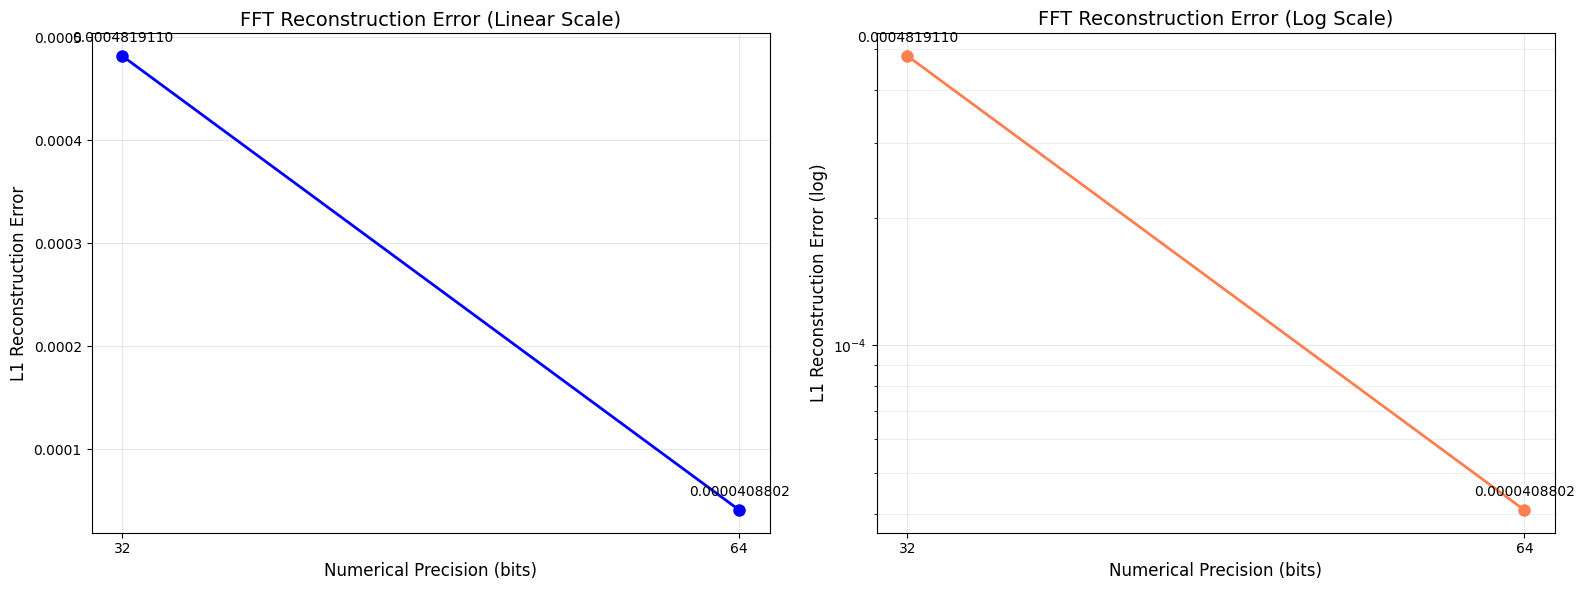

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Data from your FFT tests
precisions = [32, 64]
errors = [0.0004819110035896301, 4.088022463254182e-05]

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Regular scale plot
ax1.plot(precisions, errors, 'o-', color='blue', linewidth=2, markersize=8)
ax1.set_title('FFT Reconstruction Error (Linear Scale)', fontsize=14)
ax1.set_xlabel('Numerical Precision (bits)', fontsize=12)
ax1.set_ylabel('L1 Reconstruction Error', fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.set_xticks(precisions)

# Annotate points on linear scale
for i, (x, y) in enumerate(zip(precisions, errors)):
    ax1.annotate(f"{y:.10f}", 
                 (x, y), 
                 textcoords="offset points",
                 xytext=(0, 10), 
                 ha='center')

# Log scale plot
ax2.plot(precisions, errors, 'o-', color='coral', linewidth=2, markersize=8)
ax2.set_title('FFT Reconstruction Error (Log Scale)', fontsize=14)
ax2.set_xlabel('Numerical Precision (bits)', fontsize=12)
ax2.set_ylabel('L1 Reconstruction Error (log)', fontsize=12)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)
ax2.grid(True, which='minor', alpha=0.2)
ax2.set_xticks(precisions)

# Annotate points on log scale
for i, (x, y) in enumerate(zip(precisions, errors)):
    ax2.annotate(f"{y:.10f}", 
                 (x, y), 
                 textcoords="offset points",
                 xytext=(0, 10), 
                 ha='center')

plt.tight_layout()
# plt.savefig('fft_error_comparison.png', dpi=300)
plt.show()


Running im2col tests...
  float16 error: 0.7909393310546875
  float32 error: 8.836016058921814e-05
  float64 error: 5.2200897660607815e-05


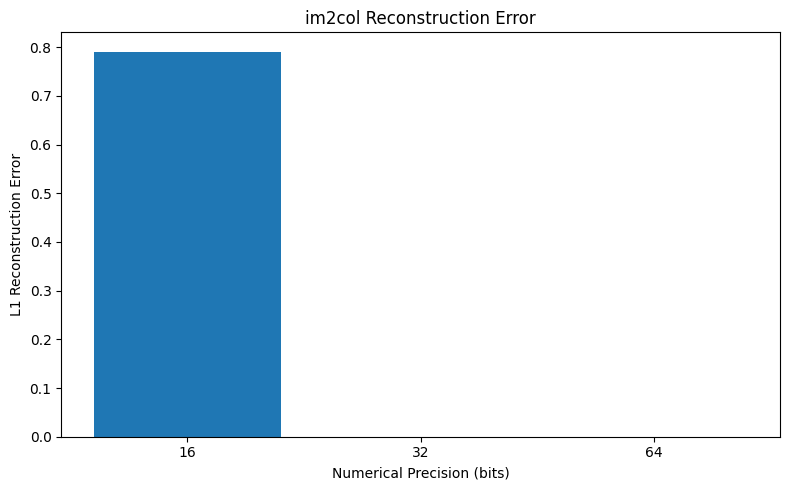

In [19]:
# Precision levels to test for im2col
precisions_im2col = [16, 32, 64]
im2col_errors = []

# Run tests for im2col at each precision
print("\nRunning im2col tests...")
for precision in precisions_im2col:
    try:
        x, k, b = conv2d_generate_test_data(precision)

        # Naive (ground truth) implementation
        naive_result = conv2d(x, k, b, method='naive')

        # im2col implementation
        im2col_result = conv2d(x, k, b, method='im2col')
        im2col_error = calculate_error(naive_result, im2col_result)
        im2col_errors.append(im2col_error)
        print(f"  float{precision} error: {im2col_error}")
    except Exception as e:
        print(f"  float{precision} failed: {str(e)}")
        im2col_errors.append(0)  # Add placeholder for plotting

# Plot im2col results
plt.figure(figsize=(8, 5))
plt.bar([str(p) for p in precisions_im2col], im2col_errors)
plt.title('im2col Reconstruction Error')
plt.xlabel('Numerical Precision (bits)')
plt.ylabel('L1 Reconstruction Error')
plt.tight_layout()
plt.show()

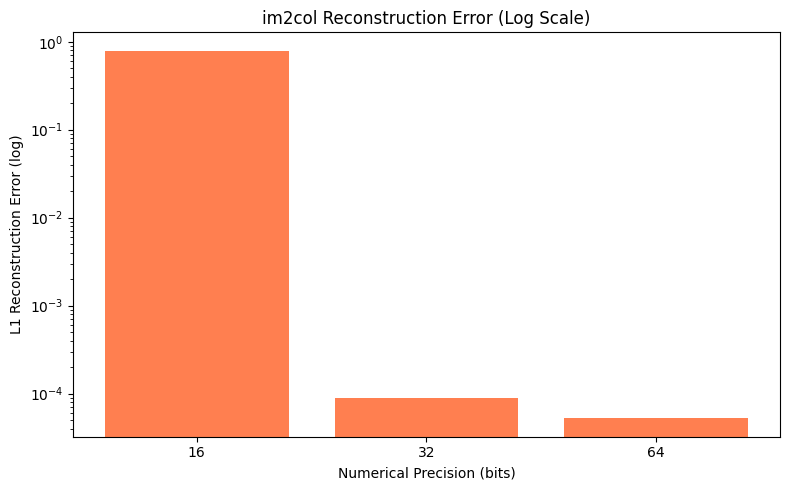

In [20]:
# Plot im2col results with log scale
plt.figure(figsize=(8, 5))
plt.bar([str(p) for p in precisions_im2col], im2col_errors, color='coral')
plt.yscale('log')  # Use log scale for y-axis
plt.title('im2col Reconstruction Error (Log Scale)')
plt.xlabel('Numerical Precision (bits)')
plt.ylabel('L1 Reconstruction Error (log)')
plt.tight_layout()
# plt.savefig('im2col_error_log_plot.png')  # Save the plot
plt.show()

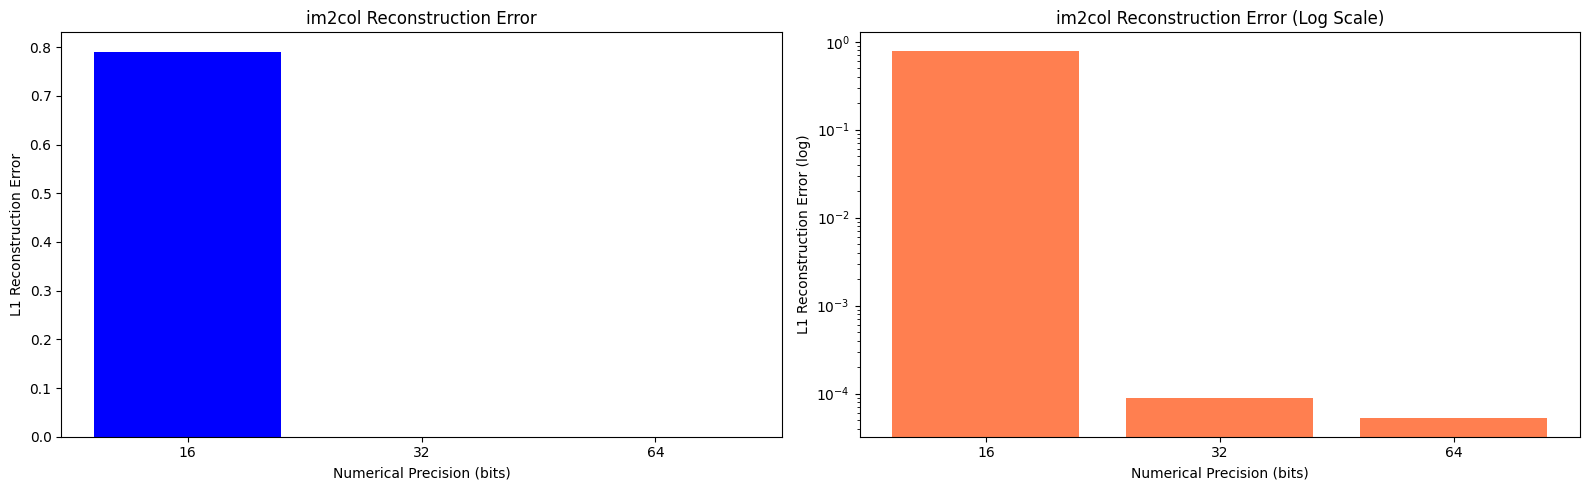

In [21]:
# Combined plot with regular and log scale side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# First subplot - regular scale
ax1.bar([str(p) for p in precisions_im2col], im2col_errors, color='blue')
ax1.set_title('im2col Reconstruction Error')
ax1.set_xlabel('Numerical Precision (bits)')
ax1.set_ylabel('L1 Reconstruction Error')

# Second subplot - log scale
ax2.bar([str(p) for p in precisions_im2col], im2col_errors, color='coral')
ax2.set_yscale('log')
ax2.set_title('im2col Reconstruction Error (Log Scale)')
ax2.set_xlabel('Numerical Precision (bits)')
ax2.set_ylabel('L1 Reconstruction Error (log)')

plt.tight_layout()
plt.show()

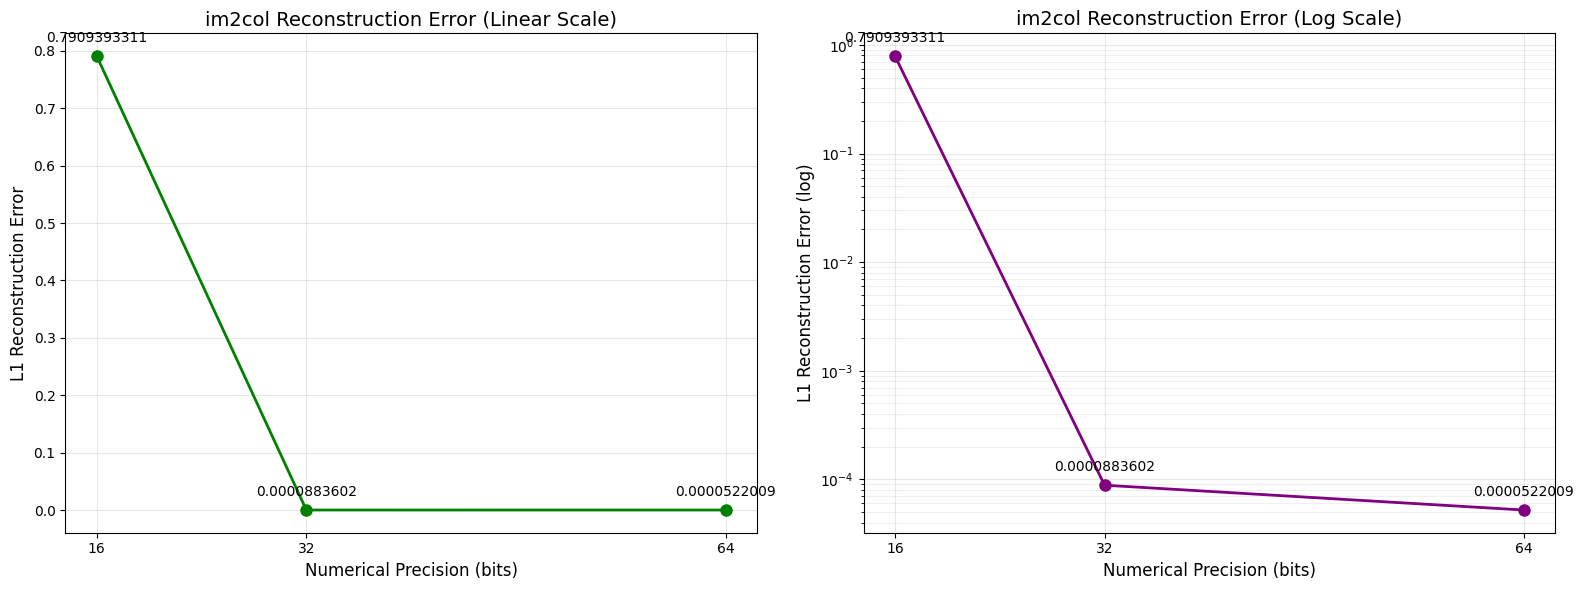

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Data from your im2col tests
precisions = [16, 32, 64]
errors = [0.7909393310546875, 8.836016058921814e-05, 5.2200897660607815e-05]

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Regular scale plot
ax1.plot(precisions, errors, 'o-', color='green', linewidth=2, markersize=8)
ax1.set_title('im2col Reconstruction Error (Linear Scale)', fontsize=14)
ax1.set_xlabel('Numerical Precision (bits)', fontsize=12)
ax1.set_ylabel('L1 Reconstruction Error', fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.set_xticks(precisions)

# Annotate points on linear scale
for i, (x, y) in enumerate(zip(precisions, errors)):
    ax1.annotate(f"{y:.10f}", 
                 (x, y), 
                 textcoords="offset points",
                 xytext=(0, 10), 
                 ha='center')

# Log scale plot
ax2.plot(precisions, errors, 'o-', color='purple', linewidth=2, markersize=8)
ax2.set_title('im2col Reconstruction Error (Log Scale)', fontsize=14)
ax2.set_xlabel('Numerical Precision (bits)', fontsize=12)
ax2.set_ylabel('L1 Reconstruction Error (log)', fontsize=12)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)
ax2.grid(True, which='minor', alpha=0.2)
ax2.set_xticks(precisions)

# Annotate points on log scale
for i, (x, y) in enumerate(zip(precisions, errors)):
    ax2.annotate(f"{y:.10f}", 
                 (x, y), 
                 textcoords="offset points",
                 xytext=(0, 10), 
                 ha='center')

plt.tight_layout()
# plt.savefig('im2col_error_comparison.png', dpi=300)
plt.show()

# 3. Matrix-matrix Multiply

In the following cell(s), please plot the reconstruction error (in the y-axis)
with the different numerical precisions (in the x-axis) for `log` (i.e.
logorithmic matrix-matrix multiplication).

In [22]:
# Set up test data
def matmul_generate_test_data(precision):
    dtype_map = {
        16: torch.float16,
        32: torch.float32,
        64: torch.float64
    }
    dtype = dtype_map[precision]

    # Create random matrices for multiplication
    # Adjust dimensions as needed for your implementation
    A = torch.randn(64, 32, dtype=dtype, device=device)
    B = torch.randn(32, 48, dtype=dtype, device=device)

    return A, B

Running Log Matrix Multiplication tests...
  float16 error: 4.9609375
  float32 error: 0.00155360484495759
  float64 error: 2.998695909639526e-12


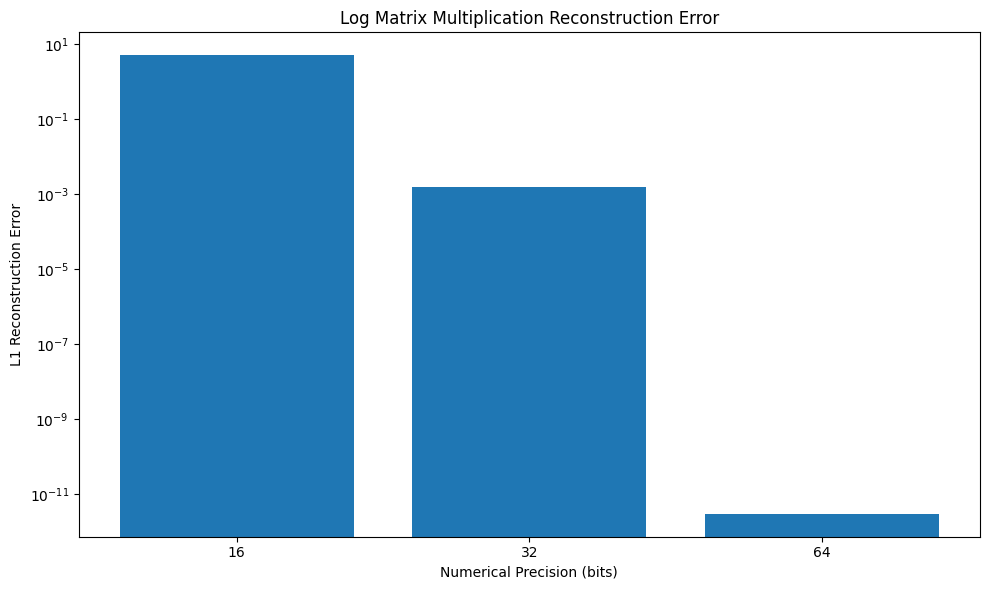

In [23]:
from src.matmul import logmatmul

# TODO: plot the error v.s. precision curve

# Precision levels to test
precisions = [16, 32, 64]
log_errors = []

# Run tests for each precision
print("Running Log Matrix Multiplication tests...")
for precision in precisions:
    A, B = matmul_generate_test_data(precision)

    # Naive (ground truth) implementation
    naive_result = matmul(A, B, method='naive')

    # Log matrix multiplication implementation
    try:
        log_result = matmul(A, B, method='log')
        log_error = calculate_error(naive_result, log_result)
        log_errors.append(log_error)
        print(f"  float{precision} error: {log_error}")
    except Exception as e:
        print(f"  float{precision} failed: {e}")
        log_errors.append(0)  # or None, to indicate failure

# Plot log matrix multiplication results
plt.figure(figsize=(10, 6))
plt.bar([str(p) for p in precisions], log_errors)
plt.title('Log Matrix Multiplication Reconstruction Error')
plt.xlabel('Numerical Precision (bits)')
plt.ylabel('L1 Reconstruction Error')
plt.yscale('log')  # Using log scale for y-axis if errors vary greatly
plt.tight_layout()
plt.show()

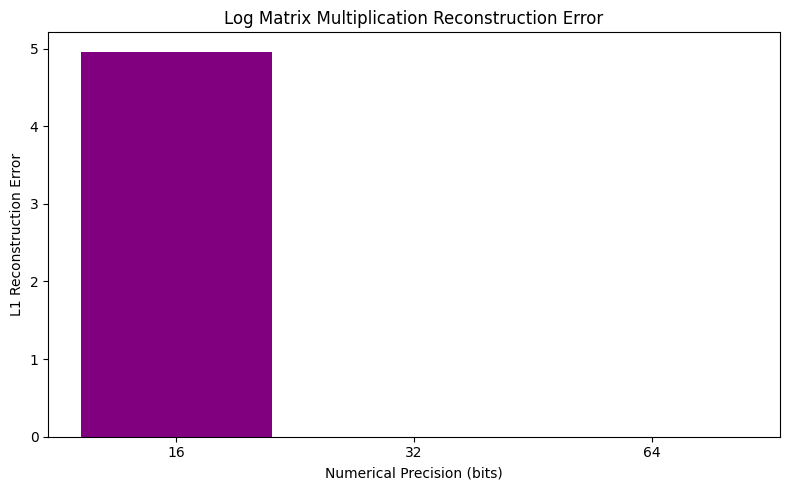

In [8]:
import matplotlib.pyplot as plt

# Hardcoded errors for each precision
precisions = [16, 32, 64]
log_errors = [4.9609375, 0.00155360484495759, 2.998695909639526e-12]

plt.figure(figsize=(8, 5))
plt.bar([str(p) for p in precisions], log_errors, color='purple')
plt.title('Log Matrix Multiplication Reconstruction Error')
plt.xlabel('Numerical Precision (bits)')
plt.ylabel('L1 Reconstruction Error')
# Do NOT use log scale
plt.tight_layout()
plt.show()

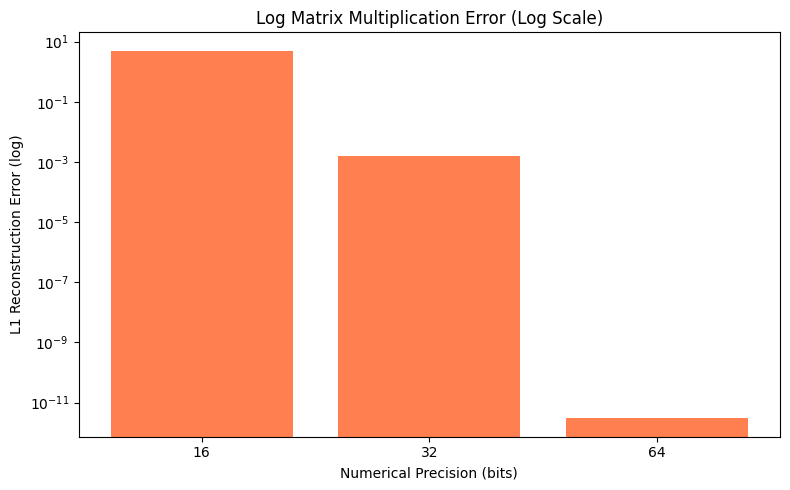

In [24]:
# Plot log matrix multiplication results with log scale
plt.figure(figsize=(8, 5))
plt.bar([str(p) for p in precisions], log_errors, color='coral')
plt.yscale('log')  # Using log scale for y-axis
plt.title('Log Matrix Multiplication Error (Log Scale)')
plt.xlabel('Numerical Precision (bits)')
plt.ylabel('L1 Reconstruction Error (log)')
plt.tight_layout()
# plt.savefig('logmatmul_error_log_plot.png')  # Save the plot
plt.show()

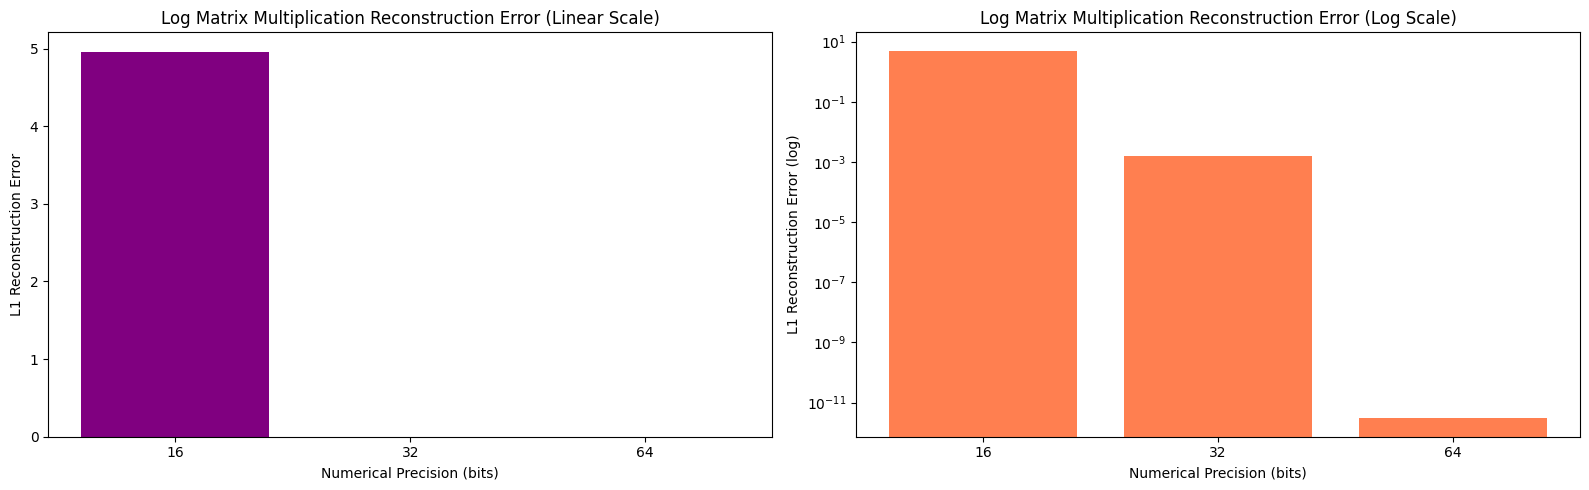

In [10]:
import matplotlib.pyplot as plt

# Hardcoded errors for each precision
precisions = [16, 32, 64]
log_errors = [4.9609375, 0.00155360484495759, 2.998695909639526e-12]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Left subplot: linear scale (regular)
ax1.bar([str(p) for p in precisions], log_errors, color='purple')
ax1.set_title('Log Matrix Multiplication Reconstruction Error (Linear Scale)')
ax1.set_xlabel('Numerical Precision (bits)')
ax1.set_ylabel('L1 Reconstruction Error')

# Right subplot: log scale
ax2.bar([str(p) for p in precisions], log_errors, color='coral')
ax2.set_yscale('log')
ax2.set_title('Log Matrix Multiplication Reconstruction Error (Log Scale)')
ax2.set_xlabel('Numerical Precision (bits)')
ax2.set_ylabel('L1 Reconstruction Error (log)')

plt.tight_layout()
plt.show()

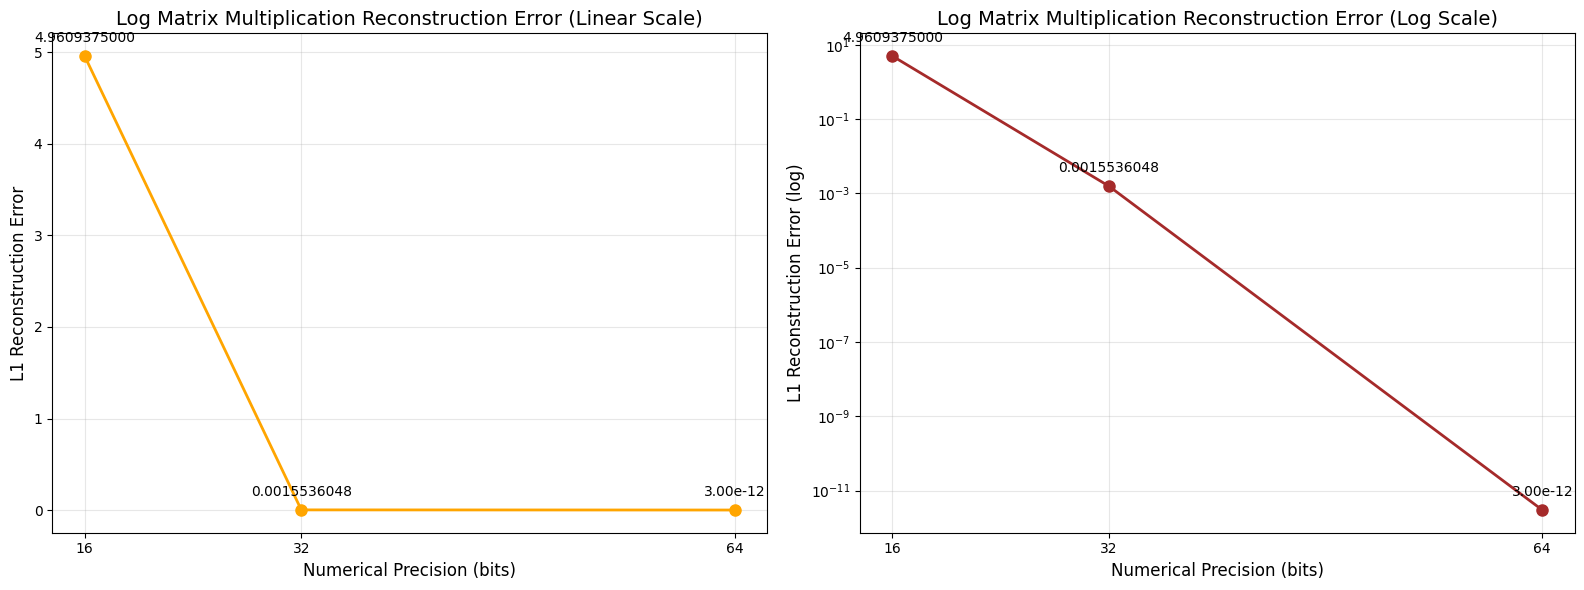

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Data from your Log Matrix Multiplication tests
precisions = [16, 32, 64]
errors = [4.9609375, 0.00155360484495759, 2.998695909639526e-12]

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Regular scale plot
ax1.plot(precisions, errors, 'o-', color='orange', linewidth=2, markersize=8)
ax1.set_title('Log Matrix Multiplication Reconstruction Error (Linear Scale)', fontsize=14)
ax1.set_xlabel('Numerical Precision (bits)', fontsize=12)
ax1.set_ylabel('L1 Reconstruction Error', fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.set_xticks(precisions)

# Annotate points on linear scale
for i, (x, y) in enumerate(zip(precisions, errors)):
    if i == 2:  # Special handling for the very small number
        ax1.annotate(f"{y:.2e}", 
                     (x, y), 
                     textcoords="offset points",
                     xytext=(0, 10), 
                     ha='center')
    else:
        ax1.annotate(f"{y:.10f}", 
                     (x, y), 
                     textcoords="offset points",
                     xytext=(0, 10), 
                     ha='center')

# Log scale plot
ax2.plot(precisions, errors, 'o-', color='brown', linewidth=2, markersize=8)
ax2.set_title('Log Matrix Multiplication Reconstruction Error (Log Scale)', fontsize=14)
ax2.set_xlabel('Numerical Precision (bits)', fontsize=12)
ax2.set_ylabel('L1 Reconstruction Error (log)', fontsize=12)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)
ax2.grid(True, which='minor', alpha=0.2)
ax2.set_xticks(precisions)

# Annotate points on log scale
for i, (x, y) in enumerate(zip(precisions, errors)):
    if i == 2:  # Special handling for the very small number
        ax2.annotate(f"{y:.2e}", 
                     (x, y), 
                     textcoords="offset points",
                     xytext=(0, 10), 
                     ha='center')
    else:
        ax2.annotate(f"{y:.10f}", 
                     (x, y), 
                     textcoords="offset points",
                     xytext=(0, 10), 
                     ha='center')

plt.tight_layout()
# plt.savefig('log_matmul_error_comparison.png', dpi=300)
plt.show()

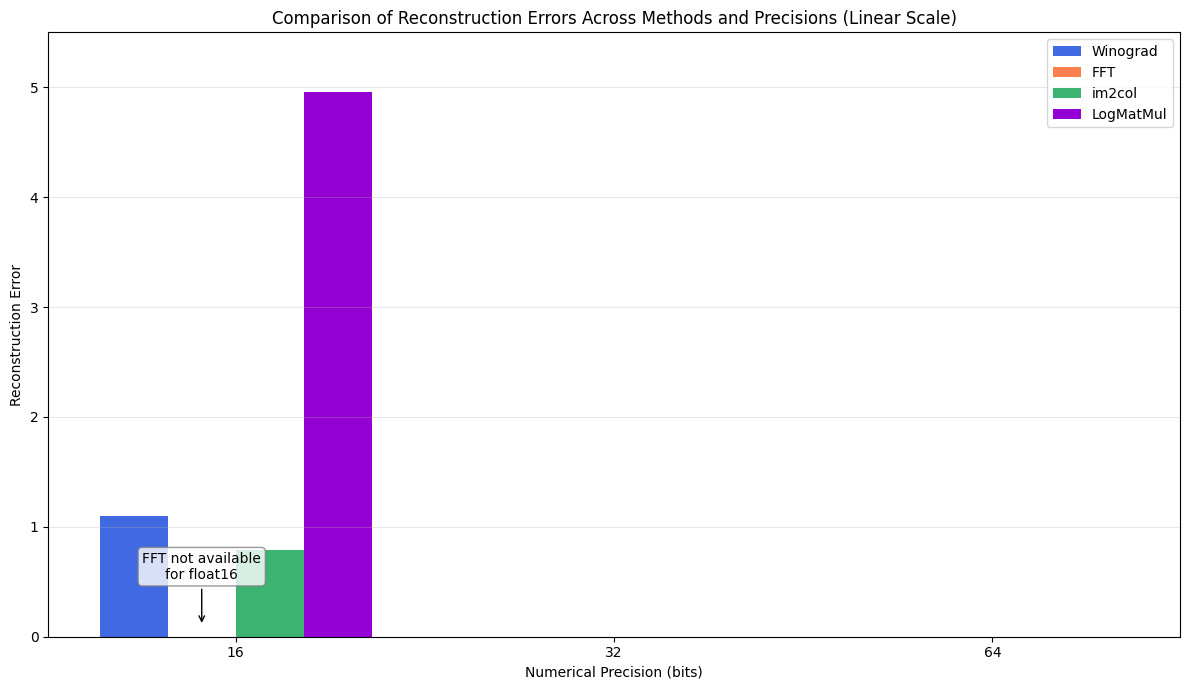


Summary of Reconstruction Errors:
Precision | Winograd | FFT | im2col | LogMatMul
-----------------------------------------------
float16   | 1.09788895e+00 | N/A | 7.90939331e-01 | 4.96093750e+00
float32   | 2.84697860e-04 | 4.81911004e-04 | 8.83601606e-05 | 1.55360484e-03
float64   | 7.34452941e-05 | 4.08802246e-05 | 5.22008977e-05 | 2.99869591e-12


In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Hardcoded values from your tests
winograd_errors = [1.0978889465332031, 0.00028469786047935486, 7.3445294100416e-05]
fft_errors = [0.0004819110035896301, 4.088022463254182e-05]
im2col_errors = [0.7909393310546875, 8.836016058921814e-05, 5.2200897660607815e-05]
log_errors = [4.9609375, 0.00155360484495759, 2.998695909639526e-12]

# Create a grouped bar chart for comparing all methods - LINEAR SCALE
plt.figure(figsize=(12, 7))

# Set width of bars and positions
bar_width = 0.18
r1 = np.arange(3)  # positions for float16, float32, float64

# We need to handle FFT separately since it doesn't have float16
precision_labels = ['16', '32', '64']
precision_values = [16, 32, 64]

# Plot winograd bars (all precisions)
plt.bar(r1 - 1.5*bar_width, winograd_errors, width=bar_width, color='royalblue', label='Winograd')

# Plot FFT bars (only for float32, float64)
# Create a version with a placeholder for float16
fft_all_precisions = [0] + fft_errors  # Add a zero placeholder for float16
plt.bar(r1 - 0.5*bar_width, fft_all_precisions, width=bar_width, color='coral', label='FFT')

# Plot im2col bars (all precisions)
plt.bar(r1 + 0.5*bar_width, im2col_errors, width=bar_width, color='mediumseagreen', label='im2col')

# Plot logmatmul bars (all precisions)
plt.bar(r1 + 1.5*bar_width, log_errors, width=bar_width, color='darkviolet', label='LogMatMul')

# Add labels, title and custom x-axis tick labels
plt.xlabel('Numerical Precision (bits)')
plt.ylabel('Reconstruction Error')
plt.title('Comparison of Reconstruction Errors Across Methods and Precisions (Linear Scale)')
plt.xticks(r1, precision_labels)
# Using linear scale
plt.legend()

# Add grid for better readability
plt.grid(axis='y', alpha=0.3)

# Add a annotation for FFT float16
plt.annotate('FFT not available\nfor float16',
             xy=(0 - 0.5*bar_width, 0.1),
             xytext=(0 - 0.5*bar_width, 0.5),
             ha='center', va='bottom',
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8),
             arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0', color='black'))

# Adjust y-axis to focus on the larger values
plt.ylim(0, 5.5)  # Adjusted to show all bars clearly

plt.tight_layout()
# plt.savefig('comparison_errors_linear.png')
plt.show()

# Print a summary table for reference
print("\nSummary of Reconstruction Errors:")
header = "Precision | Winograd | FFT | im2col | LogMatMul"
print(header)
print("-" * len(header))
for i, p in enumerate(precision_values):
    w_val = f"{winograd_errors[i]:.8e}" if winograd_errors[i] > 0 else "N/A"
    f_val = "N/A" if p == 16 else f"{fft_errors[i-1]:.8e}" if fft_errors[i-1] > 0 else "N/A"
    i_val = f"{im2col_errors[i]:.8e}" if im2col_errors[i] > 0 else "N/A"
    l_val = f"{log_errors[i]:.8e}" if log_errors[i] > 0 else "N/A"
    print(f"float{p}   | {w_val} | {f_val} | {i_val} | {l_val}")

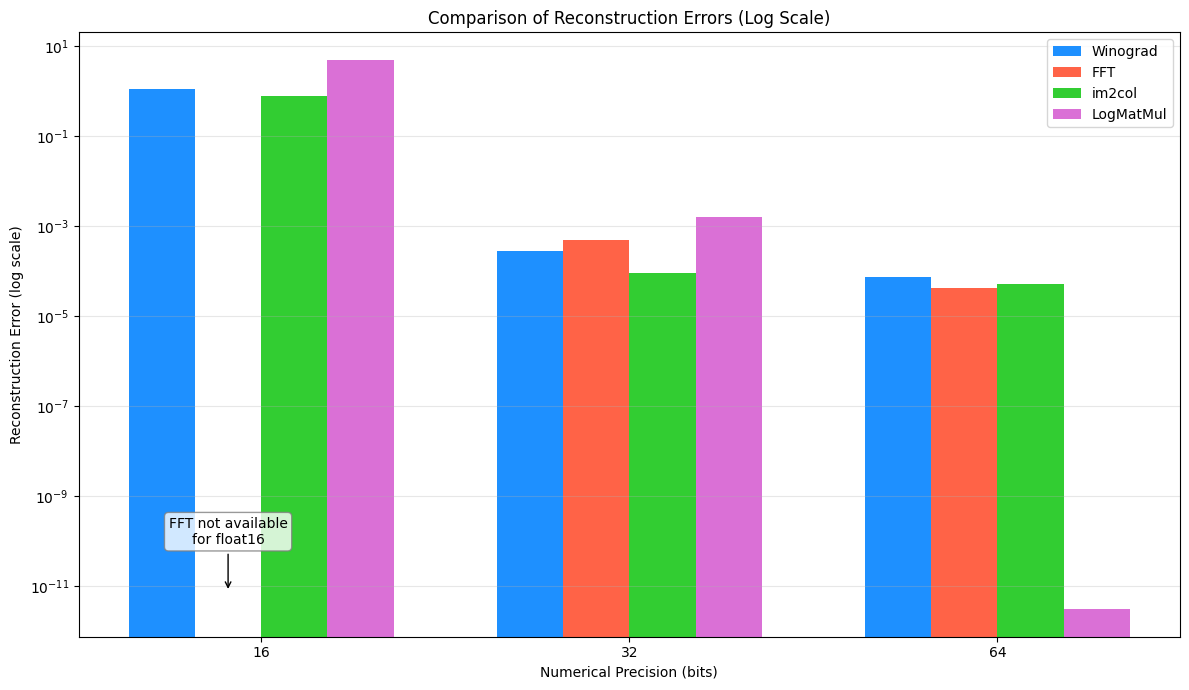

In [27]:
# Create a log-scale grouped bar chart for comparing all methods
plt.figure(figsize=(12, 7))

# Set width of bars and positions
bar_width = 0.18
r1 = np.arange(3)  # positions for float16, float32, float64

# We need to handle FFT separately since it doesn't have float16
precision_labels = ['16', '32', '64']
precision_values = [16, 32, 64]

# Use different colors for the log-scale plot
log_colors = {
    'winograd': 'dodgerblue',
    'fft': 'tomato',
    'im2col': 'limegreen',
    'logmatmul': 'orchid'
}

# Plot winograd bars (all precisions)
plt.bar(r1 - 1.5*bar_width, winograd_errors, width=bar_width, color=log_colors['winograd'], label='Winograd')

# Plot FFT bars (only for float32, float64)
# Create special positions for FFT (skip float16 position)
fft_positions = [r1[1] - 0.5*bar_width, r1[2] - 0.5*bar_width]
plt.bar(fft_positions, fft_errors, width=bar_width, color=log_colors['fft'], label='FFT')

# Plot im2col bars (all precisions)
# Replace any zeros with small values for log scale
im2col_log = [max(1e-30, e) for e in im2col_errors]
plt.bar(r1 + 0.5*bar_width, im2col_log, width=bar_width, color=log_colors['im2col'], label='im2col')

# Plot logmatmul bars (all precisions)
# Replace any zeros with small values for log scale
log_matmul_log = [max(1e-30, e) for e in log_errors]
plt.bar(r1 + 1.5*bar_width, log_matmul_log, width=bar_width, color=log_colors['logmatmul'], label='LogMatMul')

# Add labels, title and custom x-axis tick labels
plt.xlabel('Numerical Precision (bits)')
plt.ylabel('Reconstruction Error (log scale)')
plt.title('Comparison of Reconstruction Errors (Log Scale)')
plt.xticks(r1, precision_labels)
plt.yscale('log')  # Use log scale for better visibility of differences
plt.legend()

# Add grid for better readability
plt.grid(axis='y', alpha=0.3)

# Get current y-axis limits
y_bottom, y_top = plt.ylim()

# Add a annotation for FFT float16 - use visible position within the chart
plt.annotate('FFT not available\nfor float16',
             xy=(r1[0] - 0.5*bar_width, y_bottom * 10),  # Position near the bottom of the chart
             xytext=(r1[0] - 0.5*bar_width, y_bottom * 100),  # Text positioned above
             ha='center', va='bottom',
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8),
             arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0', color='black'))

plt.tight_layout()
# plt.savefig('comparison_errors_log_scale.png')
plt.show()